# 2 · Looking at the results

**Covered topics:** which arrays a relaxed `ToF` object contains and how to plot them with plain matplotlib (radial profiles, the 2D shape of the planet, the figure functions, the gravitational moments) and how to compare several models.

PyToF does not ship a plotting module. Everything it computes is a numpy array, and every figure below is a few lines of ordinary matplotlib that you can copy and adapt.

In [1]:
import inspect

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

from PyToF import ToF
from tutorial_utils import JUPITER_RADIUS, Bessel, LABELS, jupiter, profiles

plt.rcParams["figure.figsize"] = (5.2, 3.9)  # smaller default figures

## What is in a relaxed model

We use the Jupiter polytrope of notebook 1 (`jupiter()` builds and relaxes it).

A **polytrope** of index $n$ is a function relating the pressure $P$ and density $\rho$ via $P = K\rho^{1+1/n}$. The model of notebook 1 corresponds to the case $n=1$, so $\rho=\sqrt{P/K}$. Since $P$ depends only on $\rho$, the relation is called barotropic. The larger $n$, the more centrally concentrated the planet ($n=0$ would be constant density), and on log-log axes every polytrope is a straight line of $\rho$ against $P$ with the slope $n/(n+1)$. 

The planet is described by `N` nested level surfaces, ordered **from the outermost inwards**:

| attribute | meaning |
|---|---|
| `X.li` | mean radius of each level surface $l_i$ [m] |
| `X.rhoi` | density on each level surface [kg m⁻³] |
| `X.Pi` | pressure on each level surface [Pa] |
| `X.Js` | gravitational moments, `Js[n]` = $J_{2n}$ (`Js[0]` = −1) |
| `X.Js_errors` | estimated absolute errors of `X.Js`, filled by `get_Js_errors()` (same indexing as `X.Js`) |
| `X.U` | total potential (gravity plus centrifugal) on each level surface [m² s⁻²] |
| `X.figure_functions` | figure functions $s_{2n}(l)$ that describe the shape, see below |
| `X.R_eq_to_R_m`, `X.R_po_to_R_m` | equatorial and polar radius divided by the outermost mean radius |

In [2]:
X = jupiter(N=1024, order=4)
print("shapes:", X.li.shape, X.rhoi.shape, X.Pi.shape)
print("outermost level surface:", X.li[0], "m   innermost:", X.li[-1], "m")

shapes: (1024,) (1024,) (1024,)
outermost level surface: 69920443.46048169 m   innermost: 68281.68306687665 m


For plotting, four derived quantities come up again and again: normalized radius, enclosed mass, density in g/cm³ and pressure in bar. The helper `profiles()` in `tutorial_utils.py` computes them (the enclosed mass is a cumulative sum over shells):

In [3]:
print(inspect.getsource(profiles))

def profiles(X):
    """
    The four per-shell quantities that are usually plotted, as a dict of
    arrays, ordered from the outermost shell inwards, like
    X.li, X.rhoi and X.Pi.

        "r":   mean radius of the shell divided by the outermost one
        "m":   mass enclosed by the shell divided by the total mass
        "rho": density in g/cm^3
        "P":   pressure in bar
    """
    # Mass of every shell between two level surfaces, and the mass inside
    # each shell (cumulative sum from the centre outwards, O(N)):
    shell_mass = (
        4 / 3 * np.pi * (X.li**3 - np.append(X.li[1:], 0) ** 3) * X.rhoi
    )
    enclosed = np.cumsum(shell_mass[::-1])[::-1]
    return {
        "r": X.li / X.li[0],
        "m": enclosed / enclosed[0],
        "rho": X.rhoi / 1000,
        "P": X.Pi / 1e5,
    }



## Radial profiles

All four quantities at a glance. The pressure spans many orders of magnitude and is best shown on a log axis. The last panel is the barotrope itself, $\rho$ against $P$ on log-log axes, which here reproduces the input $\rho=\sqrt{P/K}$: a straight line with the polytrope slope $1/2$.

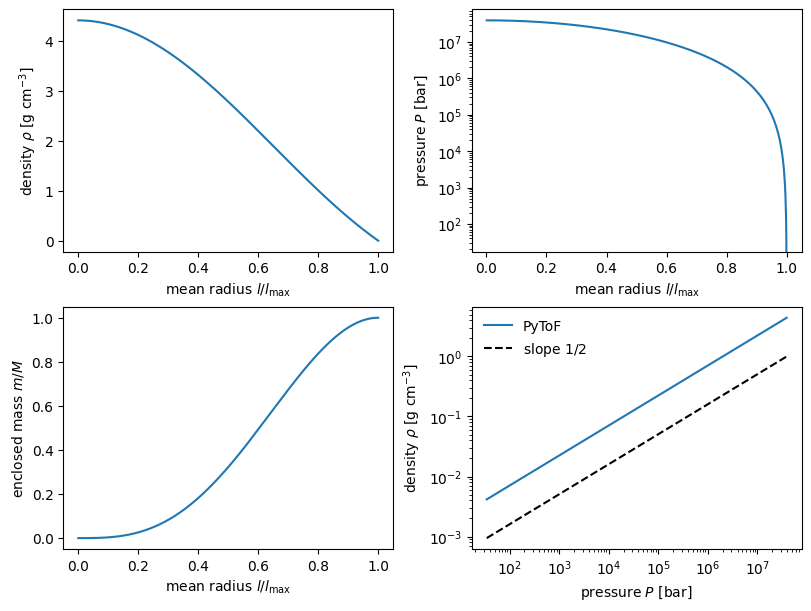

In [12]:
p = profiles(X)

fig, axs = plt.subplots(2, 2, figsize=(8, 6), layout="constrained")
axs[0, 0].plot(p["r"], p["rho"])
axs[0, 0].set_xlabel(LABELS["r"]); axs[0, 0].set_ylabel(LABELS["rho"])
axs[0, 1].plot(p["r"], p["P"])
axs[0, 1].set_yscale("log")
axs[0, 1].set_xlabel(LABELS["r"]); axs[0, 1].set_ylabel(LABELS["P"])
axs[1, 0].plot(p["r"], p["m"])
axs[1, 0].set_xlabel(LABELS["r"]); axs[1, 0].set_ylabel(LABELS["m"])
P, rho = p["P"][1:], p["rho"][1:]  # skip the surface, where P = 0
axs[1, 1].loglog(P, rho, label="PyToF")
axs[1, 1].loglog(P, (P/P[-1]) ** 0.5, "k--", label=r"slope $1/2$")
axs[1, 1].set_xlabel(LABELS["P"]); axs[1, 1].set_ylabel(LABELS["rho"])
axs[1, 1].legend(frameon=False);

## Comparing models

As an example we vary the polytropic index $n$ of the barotrope $\rho = (P/K)^{n/(n+1)}$ defined above, keeping the mass, radius and rotation of Jupiter.

n      J2            J4
1.00  1.398844e-02  -5.319627e-04
1.25  1.046025e-02  -3.240481e-04
1.50  7.695700e-03  -1.938209e-04
1.75  5.558445e-03  -1.136255e-04


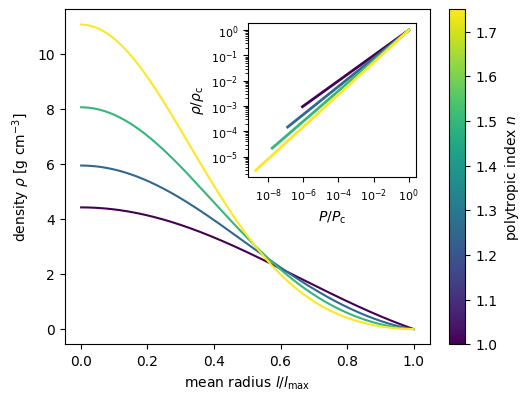

In [14]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

indices = [1.0, 1.25, 1.5, 1.75]
models = []
for n in indices:
    Y = ToF(N=1024, order=4, R_ref=JUPITER_RADIUS, baro_param=[n])
    Y.set_barotrope(lambda P, param: P ** (param[0] / (param[0] + 1)))
    Y.relax_to_barotrope()
    models.append(Y)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=min(indices), vmax=max(indices))

fig, ax = plt.subplots(layout="constrained")
ax_ins = inset_axes(ax, width="46%", height="46%", loc="upper right", borderpad=1.0)
for n, Y in zip(indices, models):
    q = profiles(Y)
    ax.plot(q["r"], q["rho"], color=cmap(norm(n)))
    # normalized to the central values (last point); skip P = 0 at the surface
    ax_ins.loglog(q["P"][1:] / q["P"][-1], q["rho"][1:] / q["rho"][-1], color=cmap(norm(n)), linewidth=2)
ax_ins.set_xlabel(r"$P / P_\mathrm{c}$")
ax_ins.set_ylabel(r"$\rho / \rho_\mathrm{c}$")
ax_ins.tick_params(labelsize=8)
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="polytropic index $n$")

print("n      J2            J4")
for n, Y in zip(indices, models):
    print(f"{n:4.2f}  {Y.Js[1]:.6e}  {Y.Js[2]:.6e}")

The table shows that $J_2$ falls with $n$: the more centrally concentrated the planet, the smaller its quadrupole. Jupiter's measured $J_2$ lies slightly above the $n=1$ value, so a one-parameter family like this one would select an index a little below 1. The inset shows $\rho$ against $P$ on log-log axes, normalized to the central values: every polytrope is a straight line, and the slopes $n/(n+1)$ fan out from $1/2$ for $n=1$ to $7/11\approx0.64$ for $n=1.75$.

## The 2D shape of the planet

`X.get_r_l_mu(mu)` returns the radius of every level surface at the given values of $\mu=\cos\vartheta$ (the cosine of the colatitude $\vartheta$) as an array of shape `(N, len(mu))`. With $x = r\sin\vartheta$ and $z = r\cos\vartheta$ we can draw a cross-section through the rotation axis, coloring each level surface by its density. Jupiter is a fast rotator, so the flattening is clearly visible. To see how far a level surface is from a sphere, the figure also shows some level surfaces (solid white) together with the sphere of the same mean radius $l$ (dashed):

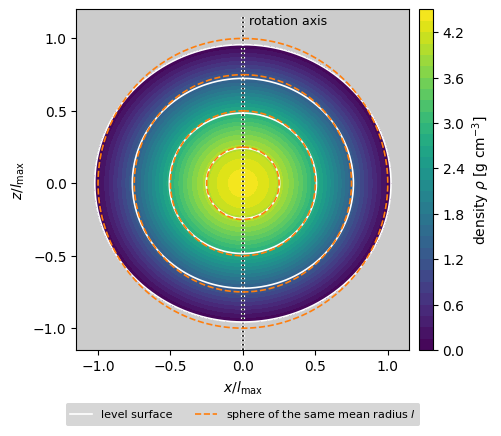

In [17]:
import matplotlib.patheffects as pe
from mpl_toolkits.axes_grid1 import make_axes_locatable

theta = np.linspace(0, 2 * np.pi, 721)  # 0..pi: right half, pi..2pi: left half
r = X.get_r_l_mu(np.cos(theta))  # (N, len(theta)), in m
xs, zs = r * np.sin(theta) / X.li[0], r * np.cos(theta) / X.li[0]
rho_shell = np.outer(X.rhoi / 1000, np.ones_like(theta))

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.set_facecolor("0.8")  # grey, so that the white lines are visible outside of the planet
cs = ax.contourf(xs, zs, rho_shell, levels=40, cmap="viridis")

# some level surfaces (solid) and the sphere of the same mean radius l (dashed):
phi = np.linspace(0, 2 * np.pi, 361)
for k, fraction in enumerate([1.0, 0.75, 0.5, 0.25]):
    i = np.argmin(np.abs(X.li / X.li[0] - fraction))
    l = X.li[i] / X.li[0]
    ax.plot(xs[i], zs[i], color="w", linewidth=1.2, label="level surface" if k == 0 else None)
    ax.plot(l * np.sin(phi), l * np.cos(phi), color="tab:orange", linestyle="--", linewidth=1.2,
            label="sphere of the same mean radius $l$" if k == 0 else None)

# rotation axis (with a white halo so that it is visible on every background):
ax.plot([0, 0], [-1.15, 1.15], "k:", linewidth=1.2, zorder=1.5, path_effects=[pe.withStroke(linewidth=3, foreground="w")])
ax.text(0.04, 1.12, "rotation axis", fontsize=9, va="center")

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.2)
ax.set_aspect("equal")
ax.set_xlabel(r"$x / l_\mathrm{max}$")
ax.set_ylabel(r"$z / l_\mathrm{max}$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, facecolor="0.8", edgecolor="none", fontsize=8)  # grey box: the white line is visible

# colorbar with exactly the height of the axes:
cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.1)
fig.colorbar(cs, cax=cax, label=LABELS["rho"]);

The same information quantitatively: how much does each level surface deviate from a sphere of its own mean radius $l$? The relative deviation $r(\vartheta)/l - 1$ is largest for the outermost surface and decreases towards the core.

R_eq/R_m = 1.02248   R_po/R_m = 0.95724   flattening 1 - R_po/R_eq = 0.0638


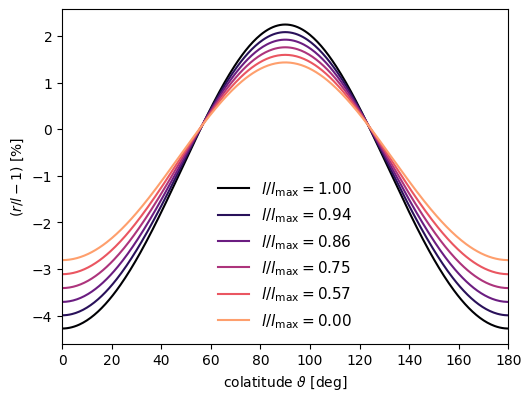

In [7]:
theta = np.linspace(0, np.pi, 361)
r = X.get_r_l_mu(np.cos(theta))
deviation = 100 * (r / X.li[:, None] - 1)  # (N, len(theta)), in %

# Level surfaces whose equatorial deviations are equally spaced, so that the
# curves are well separated (the deviation changes slowly with l):
equator = deviation[:, np.argmin(np.abs(theta - np.pi / 2))]
levels = [int(np.argmin(np.abs(equator - t))) for t in np.linspace(equator[0], equator[-1], 6)]
cmap_l = plt.get_cmap("magma")

fig, ax = plt.subplots(layout="constrained")
for k, i in enumerate(levels):
    ax.plot(np.degrees(theta), deviation[i], color=cmap_l(0.8 * k / (len(levels) - 1)), label=f"$l/l_\\mathrm{{max}} = {X.li[i] / X.li[0]:.3g}$")
ax.set_xlabel(r"colatitude $\vartheta$ [deg]")
ax.set_ylabel(r"$(r/l - 1)$ [%]")
ax.set_xlim(0, 180)
ax.legend(frameon=False, fontsize=11)
print(f"R_eq/R_m = {X.R_eq_to_R_m:.5f}   R_po/R_m = {X.R_po_to_R_m:.5f}   flattening 1 - R_po/R_eq = {1 - X.R_po_to_R_m / X.R_eq_to_R_m:.4f}")

## Figure functions

The shape is stored as the figure functions $s_{2n}(l)$ which define the level surfaces via $r(l,\mu) = l\,\bigl[1 + \sum_n s_{2n}(l)\,P_{2n}(\mu)\bigr]$ with Legendre polynomials $P_{2n}$. `X.figure_functions[n]` holds $s_{2n}$. Like `X.li`, each array runs from the outermost surface inwards. Normalized to their largest value:

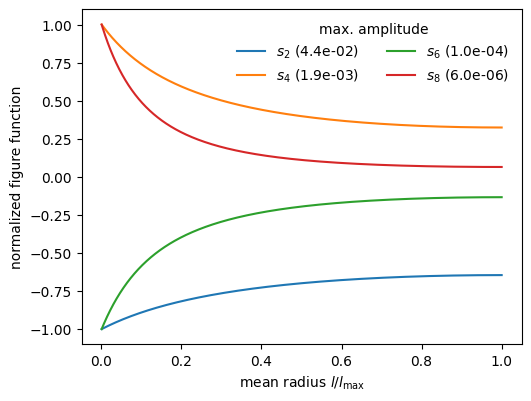

In [22]:
fig, ax = plt.subplots(layout="constrained")
for n in range(1, len(X.figure_functions)):
    s = X.figure_functions[n]
    ax.plot(X.li / X.li[0], s / np.max(np.abs(s)), label=rf"$s_{{{2 * n}}}$ ({np.max(np.abs(s)):.1e})")
ax.set_xlabel(LABELS["r"])
ax.set_ylabel("normalized figure function")
ax.legend(title="max. amplitude", frameon=False, ncol=2);

## The gravitational moments

The $|J_{2n}|$ typically fall off by roughly an order of magnitude per step, so a log axis is natural. Here with the Bessel reference and, as a lower panel, the relative error with the error estimate from `get_Js_errors()`. `X.Js_errors` holds absolute errors in the units of `X.Js`. The estimate is looked up in tables that were measured against this very Bessel solution, so for this model it falls on the actual error by construction. For other planets it tells us which error to expect at the same $N$ and order:

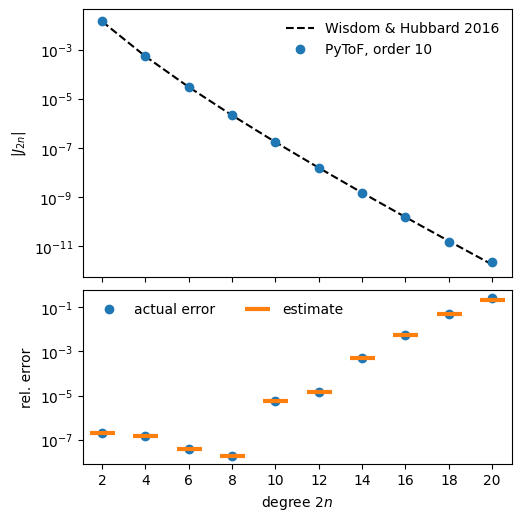

In [9]:
Z = jupiter(N=2048, order=10)
Z.get_Js_errors()
n = np.arange(1, 11)

fig, (ax, ax_err) = plt.subplots(2, 1, figsize=(5.1, 5.1), layout="constrained", sharex=True, height_ratios=[2, 1.3])
ax.plot(2 * n, np.abs(Bessel[1:]), "k--", label="Wisdom & Hubbard 2016", zorder=1)
ax.plot(2 * n, np.abs(Z.Js[1:]), "o", label="PyToF, order 10")
ax.set_yscale("log")
ax.set_ylabel(r"$|J_{2n}|$")
ax.legend(frameon=False)

ax_err.plot(2 * n, np.abs(Z.Js[1:] / Bessel[1:] - 1), "o", label="actual error")
ax_err.plot(2 * n, Z.Js_errors[1:] / np.abs(Z.Js[1:]), "_", markersize=18, markeredgewidth=3, label="estimate")
ax_err.set_yscale("log")
ax_err.set_xticks(2 * n)  # integer degrees
ax_err.set_xlabel("degree $2n$")
ax_err.set_ylabel("rel. error")
ax_err.legend(frameon=False, ncol=2);

## Takeaways

* `X.li`, `X.rhoi`, `X.Pi` are the profiles (outermost shell first), `X.figure_functions` the shape (also outermost first), `X.get_r_l_mu(mu)` the 2D surfaces.
* `X.Js` contains the gravitational moments, where `X.Js[n]` is $J_{2n}$. After calling `get_Js_errors()`, `X.Js_errors` contains estimates for the absolute errors of the gravitational moments.

Next: [3 · your own planet](03_your_own_planet.ipynb).